<a href="https://colab.research.google.com/github/Kandagatlaanoop/Prediction-of-EV-Battery-Health-Using-Machine-Learning/blob/main/EV_battery_prediction_using_Data_driven_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#RE-SECURE & UNZIP DATA

import os
import zipfile
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive safely
print("🔄 Step 1: Connecting to Google Drive...")
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')
else:
    print("✅ Drive already mounted.")

# ⚠️ TEAM RE-CHECK: If your folder in Google Drive is named something else, change it here!
drive_folder_name = 'NASA_Battery_Data'

# 2. Define exact system paths
zip_path = f'/content/drive/MyDrive/{drive_folder_name}/data.zip'
metadata_path = f'/content/drive/MyDrive/{drive_folder_name}/metadata.csv'
extract_path = '/content/data_extracted'

# 3. Check for Zip and Extract it
print("\n🔄 Step 2: Locating and unzipping data.zip...")
if os.path.exists(zip_path):
    # Create the local directory if it doesn't exist
    os.makedirs(extract_path, exist_ok=True)

    print("⚡ Unzipping high-frequency logs locally... (Should take ~20-30 seconds)")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("✅ Extraction complete! Files are now cached in local Colab memory.")

    # Quick sanity check printout
    unzipped_files = os.listdir(extract_path)
    print(f"📄 Verified: Found {len(unzipped_files)} items inside '/content/data_extracted'")
    print(f"📁 Sample files: {unzipped_files[:5]}")
else:
    print(f"❌ Error: Cannot find data.zip at: {zip_path}")
    print(f"Please look at your Google Drive and make sure the folder is named exactly '{drive_folder_name}' and contains 'data.zip'.")

# 4. Load Master Metadata Index
print("\n🔄 Step 3: Loading Master Index...")
if os.path.exists(metadata_path):
    df_meta = pd.read_csv(metadata_path)
    print(f"✅ Master Metadata Index Loaded! Tracking {len(df_meta)} rows.")
else:
    print(f"❌ Error: Cannot find metadata.csv at: {metadata_path}")

🔄 Step 1: Connecting to Google Drive...
✅ Drive already mounted.

🔄 Step 2: Locating and unzipping data.zip...
⚡ Unzipping high-frequency logs locally... (Should take ~20-30 seconds)
✅ Extraction complete! Files are now cached in local Colab memory.
📄 Verified: Found 1 items inside '/content/data_extracted'
📁 Sample files: ['data']

🔄 Step 3: Loading Master Index...
✅ Master Metadata Index Loaded! Tracking 7565 rows.


📊 Found 168 discharge cycles for battery B0005.
✅ Successfully loaded cycle log file: 05310.csv
⚡ Savitzky-Golay smoothing filters successfully applied to Voltage, Current, and Temp!


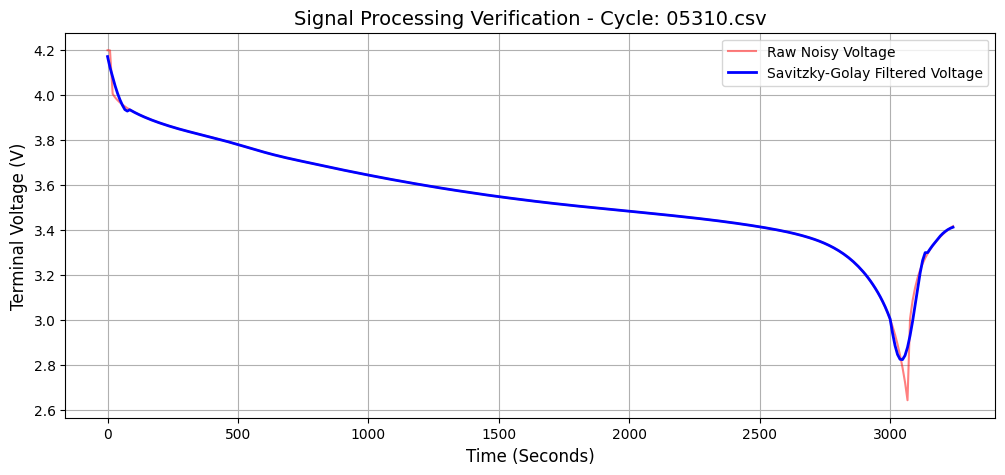

In [ ]:
#SIGNAL FILTERING
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# 1. Point directly to the folder containing the loose CSVs
base_data_path = '/content/data_extracted/data'

# 2. Filter metadata for battery B0005 and focus strictly on 'discharge' cycles
b0005_discharge = df_meta[
    (df_meta['battery_id'] == 'B0005') &
    (df_meta['type'] == 'discharge')
].sort_values(by='start_time')

print(f"📊 Found {len(b0005_discharge)} discharge cycles for battery B0005.")

# 3. Select an explicit sample cycle file to demonstrate the noise filtering
sample_filename = b0005_discharge['filename'].iloc[10] # Picking the 11th cycle
sample_file_path = os.path.join(base_data_path, sample_filename)

try:
    # 4. Load the raw time-series logs for this cycle
    cycle_df = pd.read_csv(sample_file_path)
    print(f"✅ Successfully loaded cycle log file: {sample_filename}")

    # 5. Apply the Savitzky-Golay Filter
    window = 15
    poly = 2

    cycle_df['Clean_Voltage'] = savgol_filter(cycle_df['Voltage_measured'], window_length=window, polyorder=poly)
    cycle_df['Clean_Current'] = savgol_filter(cycle_df['Current_measured'], window_length=window, polyorder=poly)
    cycle_df['Clean_Temp'] = savgol_filter(cycle_df['Temperature_measured'], window_length=window, polyorder=poly)

    print("⚡ Savitzky-Golay smoothing filters successfully applied to Voltage, Current, and Temp!")

    # 6. Plotting the results to show the professor
    plt.figure(figsize=(12, 5))
    plt.plot(cycle_df['Time'], cycle_df['Voltage_measured'], label='Raw Noisy Voltage', color='red', alpha=0.5)
    plt.plot(cycle_df['Time'], cycle_df['Clean_Voltage'], label='Savitzky-Golay Filtered Voltage', color='blue', linewidth=2)

    plt.title(f'Signal Processing Verification - Cycle: {sample_filename}', fontsize=14)
    plt.xlabel('Time (Seconds)', fontsize=12)
    plt.ylabel('Terminal Voltage (V)', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.show()

except Exception as e:
    print("❌ Error loading cycle or applying filter. Check file path structures!", e)

🧠 Initiating Phase 3: ML Feature Extraction & Model Training...
⚙️ Processing 168 cycles through the Data Pipeline...
✅ Extracted 168 valid cycle records. Matrix shape: (168, 5)

🤖 Building Level-0 Base Learners (Random Forest, SVR, XGBoost)...
🧠 Building Level-1 Meta-Learner (Linear Regression)...
🚀 Training the Hybrid Stacked Ensemble... (Please wait)

📊 --- FINAL ENSEMBLE PERFORMANCE METRICS ---
RMSE (Error Rate): 0.0204 Ah
R² Score (Accuracy): 0.9763


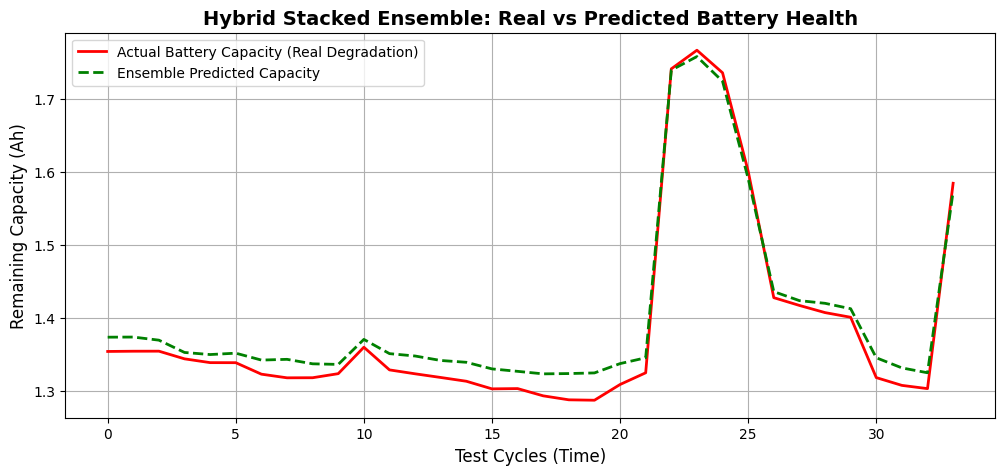

In [ ]:
# HYBRID STACKED ENSEMBLE
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("🧠 Initiating Phase 3: ML Feature Extraction & Model Training...")

# 1. Define Path
base_data_path = '/content/data_extracted/data'

# 2. Isolate B0005 Discharge Cycles
b0005_discharge = df_meta[
    (df_meta['battery_id'] == 'B0005') &
    (df_meta['type'] == 'discharge')
].sort_values(by='start_time').copy()

print(f"⚙️ Processing {len(b0005_discharge)} cycles through the Data Pipeline...")

X_list = []
y_list = []

# 3. The Feature Extraction Loop
for idx, row in b0005_discharge.iterrows():
    try:
        file_path = os.path.join(base_data_path, row['filename'])
        cycle_df = pd.read_csv(file_path)

        # Apply Savitzky-Golay
        clean_v = savgol_filter(cycle_df['Voltage_measured'], 15, 2)
        clean_c = savgol_filter(cycle_df['Current_measured'], 15, 2)
        clean_t = savgol_filter(cycle_df['Temperature_measured'], 15, 2)

        # Extract features
        feature_vector = [
            np.mean(clean_v),
            np.min(clean_v),
            np.mean(clean_c),
            np.max(clean_t),
            len(clean_v)
        ]

        X_list.append(feature_vector)

        # Find target capacity
        cap_col = 'Capacity' if 'Capacity' in row else 'capacity'
        y_list.append(row[cap_col])

    except Exception as e:
        continue

# ⚠️ THE FIX IS RIGHT HERE: Forcing Strict Numeric Types
X = np.array(X_list, dtype=np.float64)
y = np.array(y_list, dtype=np.float64)

print(f"✅ Extracted {X.shape[0]} valid cycle records. Matrix shape: {X.shape}")

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# 5. Build the Architecture
print("\n🤖 Building Level-0 Base Learners (Random Forest, SVR, XGBoost)...")
base_models = [
    ('rf', RandomForestRegressor(n_estimators=100, random_state=42)),
    ('svr', SVR(kernel='rbf', C=10, gamma='scale')),
    ('xgb', XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
]

print("🧠 Building Level-1 Meta-Learner (Linear Regression)...")
meta_model = LinearRegression()

stacked_ensemble = StackingRegressor(estimators=base_models, final_estimator=meta_model, cv=5)

# 6. Train the Master Model
print("🚀 Training the Hybrid Stacked Ensemble... (Please wait)")
stacked_ensemble.fit(X_train, y_train)

# 7. Evaluate Performance
y_pred = stacked_ensemble.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n📊 --- FINAL ENSEMBLE PERFORMANCE METRICS ---")
print(f"RMSE (Error Rate): {rmse:.4f} Ah")
print(f"R² Score (Accuracy): {r2:.4f}")

# 8. Generate the Defense Graph
plt.figure(figsize=(12, 5))
plt.plot(y_test, color='red', label='Actual Battery Capacity (Real Degradation)', linewidth=2)
plt.plot(y_pred, color='green', linestyle='dashed', label='Ensemble Predicted Capacity', linewidth=2)
plt.title('Hybrid Stacked Ensemble: Real vs Predicted Battery Health', fontsize=14, fontweight='bold')
plt.xlabel('Test Cycles (Time)', fontsize=12)
plt.ylabel('Remaining Capacity (Ah)', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

🔍 Initiating Phase 4: Cracking open the 'Black Box' with SHAP...
✅ SHAP cooperative game-theory values successfully calculated!
📊 Generating the Diagnostic Tornado Graph for the Defense Panel...



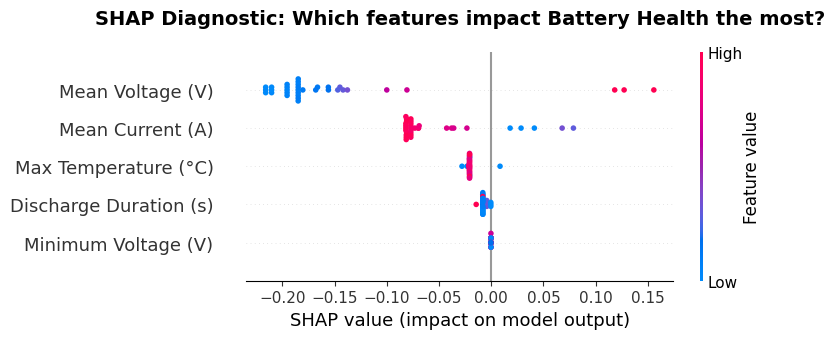

In [ ]:

# EXPLAINABLE AI (By Member 4)


# 1. Install SHAP if it's not already in Colab
!pip install shap -q
import shap
import matplotlib.pyplot as plt
print("🔍 Initiating Phase 4: Cracking open the 'Black Box' with SHAP...")
# 2. Define the exact names of the features you extracted in Phase 3
feature_names = [
    'Mean Voltage (V)',
    'Minimum Voltage (V)',
    'Mean Current (A)',
    'Max Temperature (°C)',
    'Discharge Duration (s)'
]
try:
    # 3. Extract the best Base-Learner (XGBoost) from your trained ensemble
    xgb_model = stacked_ensemble.named_estimators_['xgb']

    # 4. Initialize the SHAP Tree Explainer
    explainer = shap.TreeExplainer(xgb_model)

    # 5. Calculate the SHAP values using the exact Test Data from Phase 3
    shap_values = explainer.shap_values(X_test)

    print("✅ SHAP cooperative game-theory values successfully calculated!")
    print("📊 Generating the Diagnostic Tornado Graph for the Defense Panel...\n")

    # 6. Generate the Visual Plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_test, feature_names=feature_names, show=False)

    # Add titles to make it look highly professional
    plt.title('SHAP Diagnostic: Which features impact Battery Health the most?', fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print("❌ Error generating SHAP values. Ensure Phase 3 ran successfully first!", e)

In [ ]:

#DIGITAL TWIN and REAL-TIME SHAP XAI

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
import shap

print("🌐 Initiating Phase 5: Building the Dark Mode Digital Twin with XAI...")
# Define feature names for the graph
feature_names = ['Mean Voltage (V)', 'Min Voltage (V)', 'Mean Current (A)', 'Max Temp (°C)', 'Duration (s)']

# 1. Define the Inference Bridge (Now with SHAP!)
def predict_battery_health(mean_v, min_v, mean_c, max_t, duration):
    try:
        # Format the inputs
        input_features = np.array([[mean_v, min_v, mean_c, max_t, duration]], dtype=np.float64)

        # Make Prediction
        predicted_capacity = stacked_ensemble.predict(input_features)[0]

        # Calculate SoH
        nominal_capacity = 2.0
        soh_percentage = (predicted_capacity / nominal_capacity) * 100

        # Warnings
        if soh_percentage < 70:
            warning = "⚠️ CRITICAL: Severe Degradation. Risk of Thermal Runaway."
        elif soh_percentage < 80:
            warning = "⚠️ WARNING: Health declining. Schedule maintenance soon."
        else:
            warning = "✅ HEALTHY: Battery is operating within optimal parameters."

        # --- GENERATE REAL-TIME SHAP REASONING ---
        # Get the XGBoost model from your ensemble
        xgb_model = stacked_ensemble.named_estimators_['xgb']
        explainer = shap.TreeExplainer(xgb_model)
        shap_vals = explainer.shap_values(input_features)[0]
        # Create a real-time bar chart of the AI's reasoning
        fig, ax = plt.subplots(figsize=(6, 4))
        fig.patch.set_facecolor('#111111') # Match dark mode
        ax.set_facecolor('#111111')

        # Red if it helps capacity, Blue if it hurts capacity
        colors = ['#10b981' if val > 0 else '#ef4444' for val in shap_vals]
        bars = ax.barh(feature_names, shap_vals, color=colors)

        ax.set_title("AI Reasoning: Real-Time Feature Impact", color='white', pad=10)
        ax.set_xlabel("Impact on Capacity Prediction (Ah)", color='gray')
        ax.tick_params(axis='x', colors='gray')
        ax.tick_params(axis='y', colors='white')

        # Remove borders for a cleaner look
        for spine in ['top', 'right', 'bottom', 'left']:
            ax.spines[spine].set_visible(False)

        plt.tight_layout()

        return f"{predicted_capacity:.4f} Ah", f"{soh_percentage:.2f}%", warning, fig

    except Exception as e:
        return "Error", "Error", f"System Failure: {str(e)}", None

# 2. Build the Custom Pitch-Black Theme
dark_theme = gr.themes.Monochrome().set(
    body_background_fill="#000000",
    block_background_fill="#111111",
    block_border_color="#333333",
    button_primary_background_fill="#10b981",
    button_primary_text_color="#ffffff"
)

# 3. Design the Frontend Interface
with gr.Blocks(theme=dark_theme) as dashboard:
    gr.Markdown("<center><h1 style='color: white;'>🔋 EV Battery Digital Twin Interface</h1></center>")
    gr.Markdown("<center><h3 style='color: gray;'>Optimized Explainable Machine Learning Protocol for Battery State-of-Health Prediction</h3></center>")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 📡 Live Telemetry Inputs (Simulated OBD2)")
            mean_v_input = gr.Slider(minimum=3.0, maximum=4.2, value=3.8, label="Mean Voltage (V)")
            min_v_input = gr.Slider(minimum=2.0, maximum=3.5, value=2.7, label="Minimum Voltage (V)")
            mean_c_input = gr.Slider(minimum=-4.0, maximum=0.0, value=-1.5, label="Mean Current Draw (A)")
            max_t_input = gr.Slider(minimum=20.0, maximum=60.0, value=35.0, label="Peak Internal Temperature (°C)")
            duration_input = gr.Slider(minimum=1000, maximum=5000, value=3000, step=10, label="Discharge Duration (Seconds)")

            predict_btn = gr.Button("⚡ Run ML Inference", variant="primary")

        with gr.Column(scale=1):
            gr.Markdown("### 🧠 Stacked Ensemble AI Engine")
            cap_output = gr.Textbox(label="Predicted Remaining Capacity (Ah)")
            soh_output = gr.Textbox(label="State of Health (SoH %)")
            alert_output = gr.Textbox(label="BMS System Alert Status")

            # --- THE NEW SHAP XAI OUTPUT GRAPH ---
            gr.Markdown("### 🔍 Explainable AI (XAI) Diagnostics")
            shap_output = gr.Plot(label="Why did the AI make this prediction?")

    # Wire the buttons to the logic (Added shap_output)
    predict_btn.click(
        fn=predict_battery_health,
        inputs=[mean_v_input, min_v_input, mean_c_input, max_t_input, duration_input],
        outputs=[cap_output, soh_output, alert_output, shap_output]
    )

    dashboard.launch()

🌐 Initiating Phase 5: Building the Dark Mode Digital Twin with XAI...


/tmp/ipykernel_580/4020799531.py:73: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=dark_theme) as dashboard:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e4022ee1412ee1cde4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
